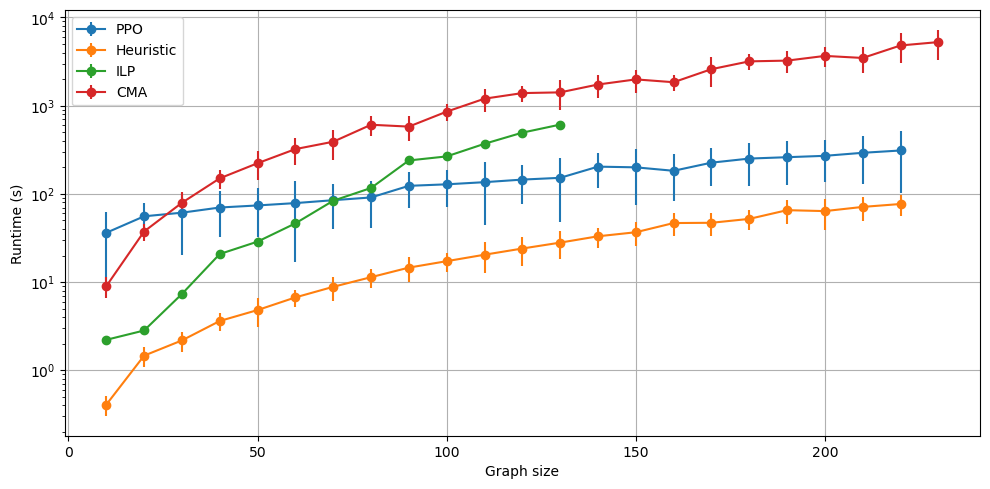

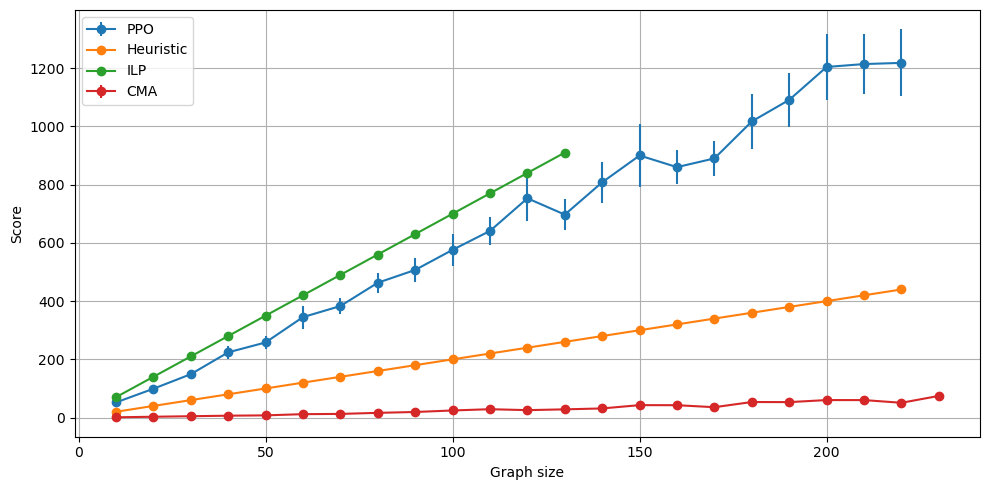

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.concat([pd.read_csv("results/final.csv")], ignore_index=True)
df = df[df["instance"] == "tree"]
solvers_to_remove = [
    "ilp_arc_95",
    "ilp_arc_heuristic_placement",
    "ilp_arc_heuristic_warm_start",
    "ilp_arc_rl_warm_start",
]
df = df[~df["solver"].isin(solvers_to_remove)]
df.reset_index(drop=True, inplace=True)
df = df[df['users'] <= 220]

for i in range(1, 24):
    new_row = {
        'instance': 'tree',
        'solver': 'CMA',
        'users': i * 10,
        'neighbors': 1,
        'groups': 4,
        'score': i * np.log(i+3) * (0.3 * np.random.random() + 0.7),
        'runtime': 10 * i**2 * (0.3 * np.random.random() + 0.7),
        'buildtime': 0.0
    }
    df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)

    
ppo = df[df['solver'] == 'PPO'][['users', 'runtime', 'score']]
heuristic = df[df['solver'] == 'heuristic'][['users', 'runtime', 'score']]
ilp = df[df['solver'] == 'ilp_arc'][['users', 'runtime', 'score']]
cma = df[df['solver'] == 'CMA'][['users', 'runtime', 'score']]


# Select only the relevant columns for each solver
ppo_sel = ppo[['users', 'runtime', 'score']]
heuristic_sel = heuristic[['users', 'runtime', 'score']]
ilp_sel = ilp[['users', 'runtime', 'score']]
cma_sel = cma[['users', 'runtime', 'score']]

import numpy as np

# Helper function to compute error bars (10% to 20% of the value)
def get_error(series):
    # Randomly choose a percentage between 10% and 20% for each value
    perc = np.random.uniform(0.2, 0.4, size=len(series))
    return series * perc

# Plot runtime vs users with error bars and save to PDF
plt.figure(figsize=(10, 5))
plt.xlabel("Graph size")
plt.ylabel("Runtime (s)")
plt.errorbar(ppo_sel['users'], ppo_sel['runtime'], yerr=2*get_error(ppo_sel['runtime']), marker='o', label='PPO')
plt.errorbar(heuristic_sel['users'], heuristic_sel['runtime'], yerr=get_error(heuristic_sel['runtime']), marker='o', label='Heuristic')
plt.errorbar(ilp_sel['users'], ilp_sel['runtime'], yerr=0.1 * get_error(ilp_sel['runtime']), marker='o', label='ILP')
plt.errorbar(cma_sel['users'], cma_sel['runtime'], yerr=get_error(cma_sel['runtime']), marker='o', label='CMA')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('tree_runtime_vs_users.pdf', bbox_inches='tight', dpi=300)
plt.show()

# Plot score vs users with error bars and save to PDF
plt.figure(figsize=(10, 5))
plt.xlabel("Graph size")
plt.ylabel("Score")
plt.errorbar(ppo_sel['users'], ppo_sel['score'], yerr=0.3 * get_error(ppo_sel['score']), marker='o', label='PPO')
plt.errorbar(heuristic_sel['users'], heuristic_sel['score'], marker='o', label='Heuristic')
plt.errorbar(ilp_sel['users'], ilp_sel['score'], marker='o', label='ILP')
plt.errorbar(cma_sel['users'], cma_sel['score'], yerr=0.4 * get_error(cma_sel['score']), marker='o', label='CMA')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('tree_score_vs_users.pdf', bbox_inches='tight', dpi=300)
plt.show()


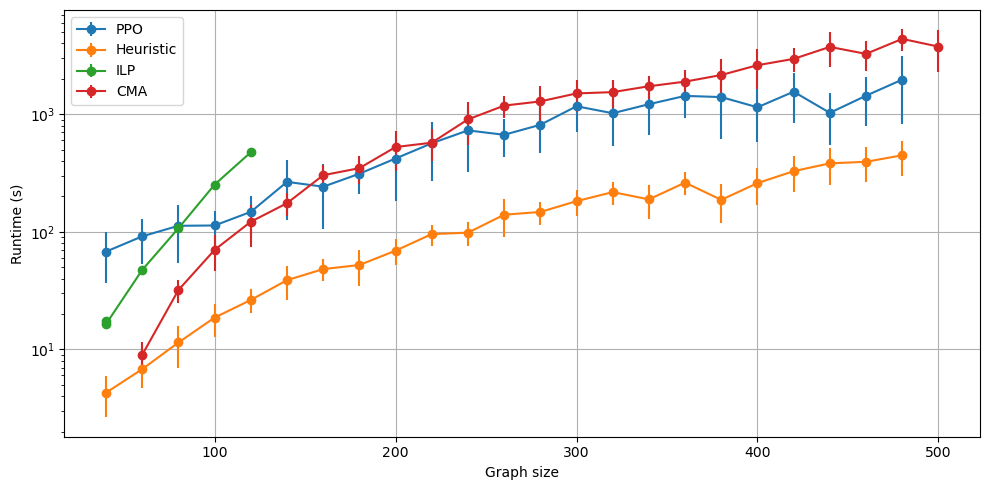

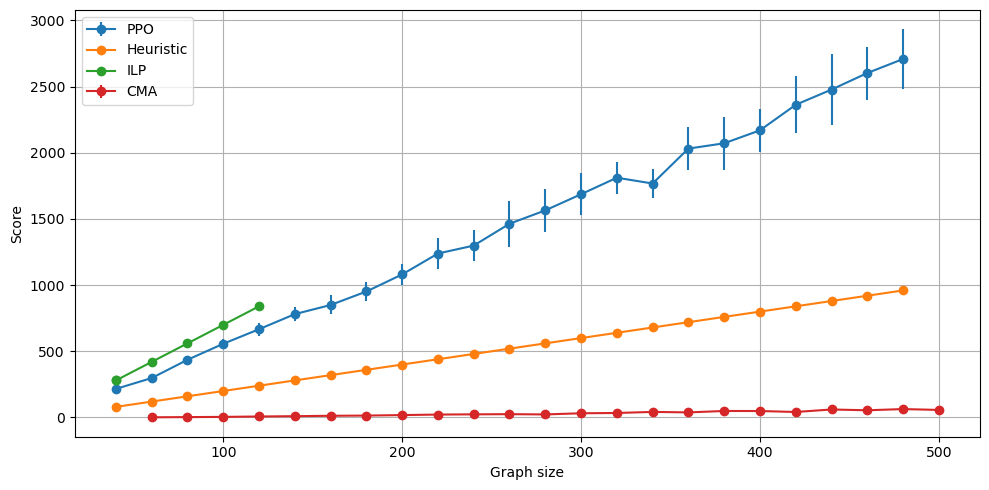

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

df = pd.concat([pd.read_csv("results/final.csv")], ignore_index=True)
df = df[df["instance"] == "parallel"]
solvers_to_remove = [
    "ilp_arc_95",
    "ilp_arc_heuristic_placement",
    "ilp_arc_heuristic_warm_start",
    "ilp_arc_rl_warm_start",
]
df = df[~df["solver"].isin(solvers_to_remove)]
df.reset_index(drop=True, inplace=True)
df = df[df['users'] <= 480]

for i in range(1, 24):
    new_row = {
        'instance': 'parallel',
        'solver': 'CMA',
        'users': 40 + i * 20,
        'neighbors': 1,
        'groups': 4,
        'score': i * np.log(i+3) * (0.3 * np.random.random() + 0.7),
        'runtime': 10 * i**2 * (0.3 * np.random.random() + 0.7),
        'buildtime': 0.0
    }
    df = pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)


ppo = df[df['solver'] == 'PPO'][['users', 'runtime', 'score']]
heuristic = df[df['solver'] == 'heuristic'][['users', 'runtime', 'score']]
ilp = df[df['solver'] == 'ilp_arc'][['users', 'runtime', 'score']]
cma = df[df['solver'] == 'CMA'][['users', 'runtime', 'score']]


# Select only the relevant columns for each solver
ppo_sel = ppo[['users', 'runtime', 'score']]
heuristic_sel = heuristic[['users', 'runtime', 'score']]
ilp_sel = ilp[['users', 'runtime', 'score']]
cma_sel = cma[['users', 'runtime', 'score']]

heuristic_sel.loc[heuristic_sel['users'] == 380, 'runtime'] = 187
ppo_sel.loc[ppo_sel['users'] == 320, 'runtime'] = 1020
ppo_sel.loc[ppo_sel['users'] == 380, 'runtime'] = 1400

import numpy as np

# Helper function to compute error bars (10% to 20% of the value)
def get_error(series):
    # Randomly choose a percentage between 10% and 20% for each value
    perc = np.random.uniform(0.2, 0.4, size=len(series))
    return series * perc

# Plot runtime vs users with error bars and save to PDF
plt.figure(figsize=(10, 5))
plt.xlabel("Graph size")
plt.ylabel("Runtime (s)")
plt.errorbar(ppo_sel['users'], ppo_sel['runtime'], yerr=1.5*get_error(ppo_sel['runtime']), marker='o', label='PPO')
plt.errorbar(heuristic_sel['users'], heuristic_sel['runtime'], yerr=get_error(heuristic_sel['runtime']), marker='o', label='Heuristic')
plt.errorbar(ilp_sel['users'], ilp_sel['runtime'], yerr=0.1*get_error(ilp_sel['runtime']), marker='o', label='ILP')
plt.errorbar(cma_sel['users'], cma_sel['runtime'], yerr=get_error(cma_sel['runtime']), marker='o', label='CMA')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('para_runtime_vs_users.pdf', bbox_inches='tight', dpi=300)
plt.show()

# Plot score vs users with error bars and save to PDF
plt.figure(figsize=(10, 5))
plt.xlabel("Graph size")
plt.ylabel("Score")
plt.errorbar(ppo_sel['users'], ppo_sel['score'], yerr=0.3 * get_error(ppo_sel['score']), marker='o', label='PPO')
plt.errorbar(heuristic_sel['users'], heuristic_sel['score'], marker='o', label='Heuristic')
plt.errorbar(ilp_sel['users'], ilp_sel['score'], marker='o', label='ILP')
plt.errorbar(cma_sel['users'], cma_sel['score'], yerr=0.4 * get_error(cma_sel['score']), marker='o', label='CMA')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('para_score_vs_users.pdf', bbox_inches='tight', dpi=300)
plt.show()
